|<h2>Course:</h2>|<h1><a href="https://udemy.com/course/dullms_x/?couponCode=202508" target="_blank">A deep understanding of AI language model mechanisms</a></h1>|
|-|:-:|
|<h2>Part 2:</h2>|<h1>Large language models<h1>|
|<h2>Section:</h2>|<h1>Pretrain LLMs<h1>|
|<h2>Lecture:</h2>|<h1><b>CodeChallenge: SGD vs. Adam vs. AdamW<b></h1>|

<br>

<h5><b>Teacher:</b> Mike X Cohen, <a href="https://sincxpress.com" target="_blank">sincxpress.com</a></h5>
<h5><b>Course URL:</b> <a href="https://udemy.com/course/dullms_x/?couponCode=202508" target="_blank">udemy.com/course/dullms_x/?couponCode=202508</a></h5>
<i>Using the code without the course may lead to confusion or errors.</i>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

# vector plots
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

# Pre-exercise example

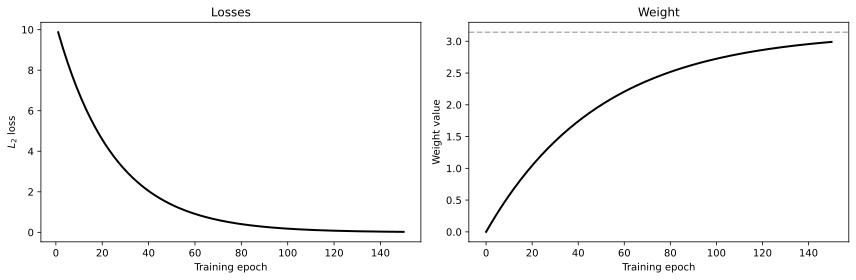

In [ ]:
# initialize weight value
w = torch.tensor([0.], requires_grad=True)
                    # By setting requires_grad=True, python will create an entire computational graph to associate with the variable w.
                    # And that's what is necessary for allowing us to train this model using an optimizer.

# target value
target = torch.tensor([torch.pi])
                    # The target value is Pi. We don't need a gradient information (don't need requires_grad=True) on this variable.
                    # This is th enumber that we are working towards.

# learning rate
lr = .01

# create the optimizers
optimizer = torch.optim.SGD([w],lr=lr)    # SDG here is stochastic gradient decent optimizer.

# number of training iterations
numIters = 150                            # specify 150 training epochs

# initialize results matrices
all_losses  = np.zeros(numIters)          # Zero out gradients
all_weights = np.zeros(numIters+1)
all_weights[0] = w.item() # initial value


### training loop
for i in range(numIters):

  # train the weight
  optimizer.zero_grad()
  loss = (w - target)**2                  # Using L2 loss
  loss.backward()                         # Calculate the gradients
  optimizer.step()                        # Update the weights

  # store the loss and update the weight value
  all_losses[i] = loss.item()             # Storing the loss
  all_weights[i+1] = w.item()             # Storing the actual weight parameter value



#### visualization
_,axs = plt.subplots(1,2,figsize=(12,4))

# plot the losses and weight values
axs[0].plot(range(1,numIters+1),all_losses,'k',linewidth=2)       # Plot all the losses
axs[1].plot(range(0,numIters+1),all_weights,'k',linewidth=2)      # Pot all the weight values as they are changing 
                                                                  # over the course of learning.

axs[0].set(title='Losses',ylabel='$L_2$ loss',xlabel='Training epoch')
axs[1].set(title='Weight',ylabel='Weight value',xlabel='Training epoch')
axs[1].axhline(target,linestyle='--',color=[.7,.7,.7],label='Target')

plt.tight_layout()
plt.show()

# Exercise 1: The optimizer competition :0

In [ ]:
# initialize weight value
wSGD   = torch.tensor([2.], requires_grad=True)
wAdam  = torch.tensor([2.], requires_grad=True)
wAdamW = torch.tensor([2.], requires_grad=True)

# target value
target = torch.tensor([5.])

# learning rates (equal for exercises 1&3; changed in exercise 2)
learningrateSGD = .05
learningrateAdm = .05

# create the optimizers
optimizerSGD   = torch.optim.SGD([wSGD],    lr=learningrateSGD)
optimizerAdam  = torch.optim.Adam([wAdam],  lr=learningrateAdm)
optimizerAdamW = torch.optim.AdamW([wAdamW],lr=learningrateAdm)

# number of training iterations
numIters = 50

# initialize results matrices
all_losses  = np.zeros((3,numIters))      # This zeros vector will be use for Storing losses of all three independent parameter values (weights).
all_weights = np.zeros((3,numIters+1))
all_weights[:,0] = wSGD.item()


# training loop
for i in range(numIters):

  # train the SGD weight
  optimizerSGD.zero_grad()
  lossSGD = (wSGD - target)**2
  lossSGD.backward()
  optimizerSGD.step()

  # train with Adam
  optimizerAdam.zero_grad()
  lossAdam = (wAdam - target)**2
  lossAdam.backward()
  optimizerAdam.step()

  # train with AdamW
  optimizerAdamW.zero_grad()
  lossAdamW = (wAdamW - target)**2
  lossAdamW.backward()
  optimizerAdamW.step()

  # store the losses and updated weight value
  all_losses[0,i] = lossSGD.item()
  all_losses[1,i] = lossAdam.item()
  all_losses[2,i] = lossAdamW.item()

  all_weights[0,i+1] = wSGD.item()
  all_weights[1,i+1] = wAdam.item()
  all_weights[2,i+1] = wAdamW.item()


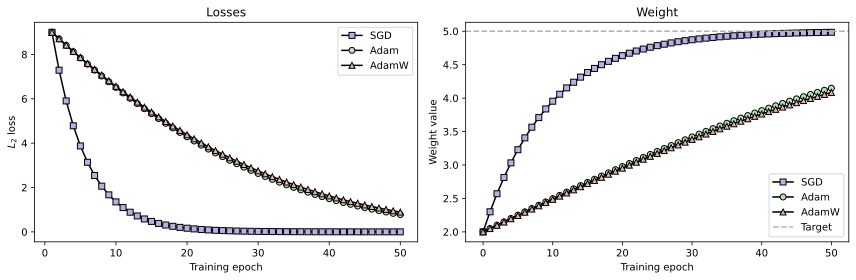

In [4]:
_,axs = plt.subplots(1,2,figsize=(12,4))

# labels and markers
optimlabels = [ 'SGD','Adam','AdamW' ]
markercols = [ [.7,.7,.9],[.7,.9,.7],[.9,.7,.7] ]
shapes = 'so^'


# loop over the optimizers and plot
for i in range(3):

  # plot the losses
  axs[0].plot(range(1,numIters+1),all_losses[i,:],'k',marker=shapes[i],
              markerfacecolor=markercols[i],label=optimlabels[i])

  # plot the weight
  axs[1].plot(range(0,numIters+1),all_weights[i,:],'k',marker=shapes[i],
              markerfacecolor=markercols[i],label=optimlabels[i])


axs[0].set(title='Losses',ylabel='$L_2$ loss',xlabel='Training epoch')
axs[1].set(title='Weight',ylabel='Weight value',xlabel='Training epoch')
axs[1].axhline(target,linestyle='--',color=[.7,.7,.7],label='Target')
for a in axs: a.legend()

plt.tight_layout()
plt.show()

# Exercise 2: Adjust the learning rates

In [5]:
# I used:
learningrateSGD = .04
learningrateAdm = .1

# Exercise 3: Without resetting gradients

In [6]:
# add this line:
print(f'{wAdam.grad.item():7.3f} {wAdamW.grad.item():7.3f}')

 -1.765  -1.889
